<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/lab2_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 – Instal FAISS
FAISS merupakan library untuk pencarian kemiripan dan nearest neighbor. Untuk praktikum ini gunakan versi CPU. Jika menggunakan lingkungan GPU yang telah dikonfigurasi khusus, instalasi GPU mengikuti dukungan platform.

In [1]:
!pip install -q faiss-cpu

## Langkah 2 – Import Library
NumPy digunakan untuk membuat dan mengolah dataset, FAISS untuk pencarian nearest neighbor, Matplotlib untuk visualisasi, dan `time` untuk mengukur waktu komputasi.

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

print('FAISS version:', getattr(faiss, '__version__', 'unknown'))

FAISS version: 1.15.1


## Langkah 3 – Membuat Dummy Dataset
Dataset dibuat secara acak sebanyak 1.000 titik dalam ruang dua dimensi. Tipe data diubah menjadi `float32` karena FAISS mengharapkan input vektor bertipe float32. Query point ditetapkan pada koordinat `[0.5, 0.5]`.

In [3]:
# Build random data
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 data 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query point

print('Bentuk dataset:', X.shape)
print('Tipe data:', X.dtype)
print('Query point:', query)

Bentuk dataset: (1000, 2)
Tipe data: float32
Query point: [[0.5 0.5]]


## Langkah 4 – Membuat Model Exact NN (IndexFlatL2)
`IndexFlatL2` melakukan pencarian menyeluruh sehingga hasilnya menjadi acuan Exact NN. Index dibangun dengan dimensi 2, kemudian seluruh data ditambahkan. Setelah itu dicari 3 tetangga terdekat dari query.

**Catatan penting:** FAISS `IndexFlatL2` mengembalikan kuadrat jarak Euclidean (squared L2 distance), bukan akar jaraknya.

In [4]:
# Search NN using Exact NN
index_flat = faiss.IndexFlatL2(2)   # L2 = squared Euclidean distance
index_flat.add(X)

# Compute Exact NN Time (search only)
start = time.perf_counter()
D_flat, I_flat = index_flat.search(query, 3)  # Find 3 NN
end = time.perf_counter()
time_flat = end - start

print('Exact NN indices:', I_flat)
print('Exact NN squared distances:', D_flat)
print('Waktu Exact:', time_flat, 'detik')

Exact NN indices: [[137 170 750]]
Exact NN squared distances: [[0.00013095 0.00077404 0.00079751]]
Waktu Exact: 0.0002686899999844172 detik


## Langkah 5 – Membuat Model FAISS IVF+PQ
Pada tahap ini digunakan pendekatan Inverted File (IVF) dan Product Quantization (PQ). IVF membagi data ke dalam cluster, sedangkan PQ melakukan kompresi representasi vektor. Model perlu dilatih menggunakan dataset sebelum data ditambahkan dan pencarian dilakukan.

Parameter mengikuti modul: `nlist = 10`, `m = 2`, dan `8` bit per subvector.

In [5]:
# Compute FAISS IVF + PQ
nlist = 10   # number of inverted lists / clusters
m = 2        # number of subvectors
quantizer = faiss.IndexFlatL2(2)  # quantizer for IVF clustering
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)

# Train the index, then add dataset
index_ivfpq.train(X)
index_ivfpq.add(X)

# Search 3 nearest neighbors (search time only)
start = time.perf_counter()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.perf_counter()
time_ivfpq = end - start

print('IVF+PQ indices:', I_ivfpq)
print('IVF+PQ squared distances:', D_ivfpq)
print('Waktu IVF+PQ:', time_ivfpq, 'detik')

IVF+PQ indices: [[137 170 750]]
IVF+PQ squared distances: [[0.00012945 0.00079226 0.00080067]]
Waktu IVF+PQ: 0.00028410599998096586 detik


## Langkah 6 – Mengecek Hasil Performa
Bandingkan indeks tetangga, jarak, dan waktu pencarian kedua metode. Waktu yang dicatat adalah waktu pencarian (*search time*), bukan waktu pembuatan index, pelatihan IVF+PQ, atau penambahan data.

Karena IVF+PQ bersifat approximate, hasil indeks dan jaraknya dapat berbeda dari Exact NN. Pada dataset kecil, perbedaan waktu juga dapat dipengaruhi overhead dan variasi pengukuran.

In [6]:
# Print the performances
print('Exact NN (Flat) indices:', I_flat, 'distances:', D_flat)
print('IVF+PQ indices:', I_ivfpq, 'distances:', D_ivfpq)
print('Waktu Exact:', time_flat, 'detik')
print('Waktu IVF+PQ:', time_ivfpq, 'detik')

same_indices = np.array_equal(I_flat, I_ivfpq)
print('Apakah indeks hasil kedua metode sama?', same_indices)

if time_ivfpq > 0:
    print('Rasio waktu Exact / IVF+PQ:', time_flat / time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0002686899999844172 detik
Waktu IVF+PQ: 0.00028410599998096586 detik
Apakah indeks hasil kedua metode sama? True
Rasio waktu Exact / IVF+PQ: 0.9457385623760799


## Langkah 7 – Visualisasi
Visualisasi memperlihatkan seluruh titik dataset, query point, hasil Exact NN, dan hasil IVF+PQ. Titik tetangga yang sama dari kedua metode dapat terlihat saling bertumpuk.

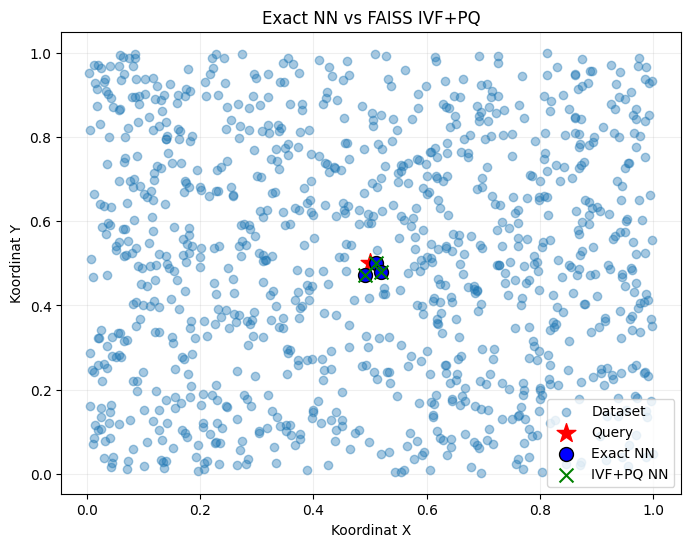

In [7]:
# Visualize
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label='Dataset')
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label='Query')

# Flat NN -> Exact NN
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100,
            edgecolor='k', label='Exact NN')
# IVF+PQ NN -> FAISS
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x',
            s=100, label='IVF+PQ NN')

plt.legend()
plt.title('Exact NN vs FAISS IVF+PQ')
plt.xlabel('Koordinat X')
plt.ylabel('Koordinat Y')
plt.grid(alpha=0.2)
plt.show()

## Analisis dan Kesimpulan

`IndexFlatL2` memberikan hasil pencarian exact, sedangkan IVF+PQ menggunakan pengelompokan dan kuantisasi untuk mendukung pencarian approximate yang dapat lebih efisien pada skala data besar. Performa aktual harus dinilai berdasarkan akurasi tetangga dan pengukuran waktu pada dataset serta perangkat yang digunakan.

### Catatan interpretasi
Nilai jarak `D_flat` dan `D_ivfpq` dari FAISS merupakan squared L2 distance. Jangan menyebutnya jarak Euclidean biasa tanpa mengambil akar kuadrat. Selain itu, parameter `nprobe` tidak diubah pada percobaan ini sehingga menggunakan nilai default FAISS.